# Lecture 11: Unsupervised GMM and EM algorithm Code Companion

## Normal (Gaussian) Distribution

A [multivariate normal](https://en.wikipedia.org/wiki/Multivariate_normal_distribution) distribution with parameters $\theta = (\mu, \Sigma)$
is a probability over a $d$-dimensional $x \in \mathbb{R}^d$

$$
\mathcal{N}(x; \mu, \Sigma) = \frac{1}{\sqrt{(2 \pi)^d | \Sigma |}} \exp\left(-\frac{1}{2} (x - \mu)^\top \Sigma^{-1} (x-\mu) \right)
$$

In one dimension, this reduces to $\frac{1}{\sqrt{2 \pi}\sigma} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2} \right)$.

# Gaussian Mixture Models: An Example

GMMs are a probabilistic generative models $P_\theta(x,z)=P_\theta(x|z) P_\theta(z)$ that can be used for clustering.

\begin{align*}
P_\theta(x|y=\text{0}) = \mathcal{N}(x; \mu_0, \Sigma_0) && P_\theta(x|y=\text{1}) = \mathcal{N}(x; \mu_1, \Sigma_1) && \text{etc.}
\end{align*}

We also define $P_\theta(y=\text{0}) = \phi_0$, $P_\theta(y=\text{1}) = \phi_1$, etc.

The data probability is then written as:

\begin{align*}
P_\theta(x) & = P_\theta(x | z=0) \cdot P_\theta(z=0) + P_\theta(x | z=1) \cdot P_\theta(z=1)\\
& = \mathcal{N}(x; \mu_0, \Sigma_0) \cdot \phi_0 + \mathcal{N}(x; \mu_1, \Sigma_1) \cdot \phi_1
\end{align*}


# Warm-Up: Clustering With Known Cluster Assignments

Suppose we have a dataset $\mathcal{D} = \{(x^{(1)}, z^{(1)}), (x^{(2)}, z^{(2)}), \ldots, (x^{(n)}, z^{(n)})\}$, where the identity of each cluster is known.

* $x^{(i)} \in \mathbb{R}$ are the datapoints we cluster
* $z^{(i)} \in \{1,2,...,K\}$ are the cluster IDs
* We will fit a GMM, the $\mu_k$ will represent the cluster centroids.

How would we do this?

This is the same problem as in Gaussian Distriminant Analysis (GDA). We can fit a GMM to this data as follows:

1. We fit the parameters $\phi_k$ to be % of each class $k$ in $\mathcal{D}$.
2. We fit the parameters $\mu_k, \Sigma_k$ to be means and variances of each class $k$.
3. We can infer the cluster ID $z$ of new points using $P(z|x)$ as in GDA.

Let's look at an example on our Iris flower dataset.

In [14]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
from sklearn import datasets

# Load the Iris dataset
iris = datasets.load_iris(as_frame=True)

# print part of the dataset
iris_X, iris_y = iris.data, iris.target
pd.concat([iris_X, iris_y], axis=1).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Recall that we have previously seen how to fit GMMs on a labeled $(x,y)$ dataset using using maximum likelihood.

Let's try this on our Iris dataset again (recall that this is called GDA).

In [15]:
# we can implement these formulas over the Iris dataset
X = iris_X.to_numpy()[:,:2]
d = 2 # number of features in our toy dataset
K = 3 # number of clases
n = X.shape[0] # size of the dataset

# these are the shapes of the parameters
mus = np.zeros([K,d])
Sigmas = np.zeros([K,d,d])
phis = np.zeros([K])

# we now compute the parameters
for k in range(3):
    X_k = X[iris_y == k]
    mus[k] = np.mean(X_k, axis=0)
    Sigmas[k] = np.cov(X_k.T)
    phis[k] = X_k.shape[0] / float(n)

This code lets us generate predictions from the GMM model that we just learned by implementing Bayes' rule.

In [16]:
# we can implement this in numpy
def gda_predictions(x, mus, Sigmas, phis):
    """This returns class assignments and p(y|x) under the GDA model.
    
    We compute \arg\max_y p(y|x) as \arg\max_y p(x|y)p(y)
    """
    # adjust shapes
    n, d = x.shape
    x = np.reshape(x, (1, n, d, 1))
    mus = np.reshape(mus, (K, 1, d, 1))
    Sigmas = np.reshape(Sigmas, (K, 1, d, d))    
    
    # compute probabilities
    py = np.tile(phis.reshape((K,1)), (1,n)).reshape([K,n,1,1])
    pxy = (
        np.sqrt(np.abs((2*np.pi)**d*np.linalg.det(Sigmas))).reshape((K,1,1,1)) 
        * -.5*np.exp(
            np.matmul(np.matmul((x-mus).transpose([0,1,3,2]), np.linalg.inv(Sigmas)), x-mus)
        )
    )
    pyx = pxy * py
    return pyx.argmax(axis=0).flatten(), pyx.reshape([K,n])

idx, pyx = gda_predictions(X, mus, Sigmas, phis)

We can visualize the GMM as follows:

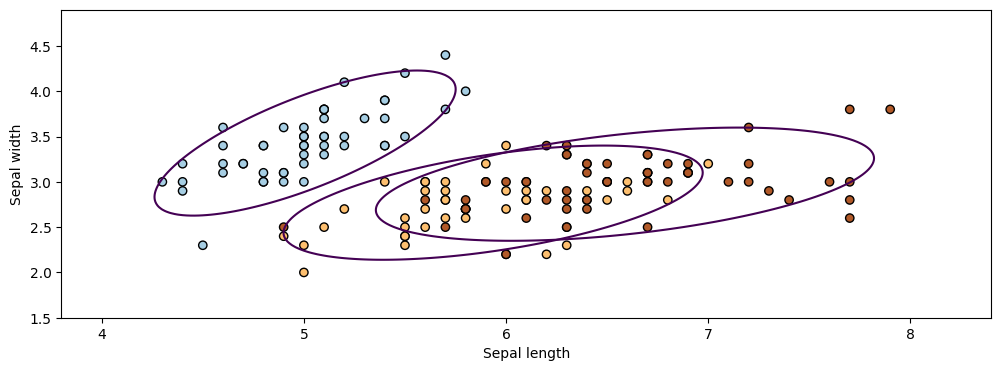

In [17]:
# https://scikit-learn.org/stable/auto_examples/neighbors/plot_classification.html
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
plt.rcParams['figure.figsize'] = [12, 4]

x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, .02), np.arange(y_min, y_max, .02))
Z, pyx = gda_predictions(np.c_[xx.ravel(), yy.ravel()], mus, Sigmas, phis)
logpy = np.log(-1./3*pyx)

# Put the result into a color plot
Z = Z.reshape(xx.shape)
contours = np.zeros([K, xx.shape[0], xx.shape[1]])
for k in range(K):
    contours[k] = logpy[k].reshape(xx.shape)
for k in range(K):
    plt.contour(xx, yy, contours[k], levels=np.logspace(0, 1, 1))

# Plot also the training points
plt.scatter(X[:, 0], X[:, 1], c=iris_y, edgecolors='k', cmap=plt.cm.Paired)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')

plt.show()

In the above example, the $P_\theta(z|x)$ from the GMM $P_\theta$ tells us the cluster ID $z$ of $x$.

But what if we don't have labels to train $P_\theta$?

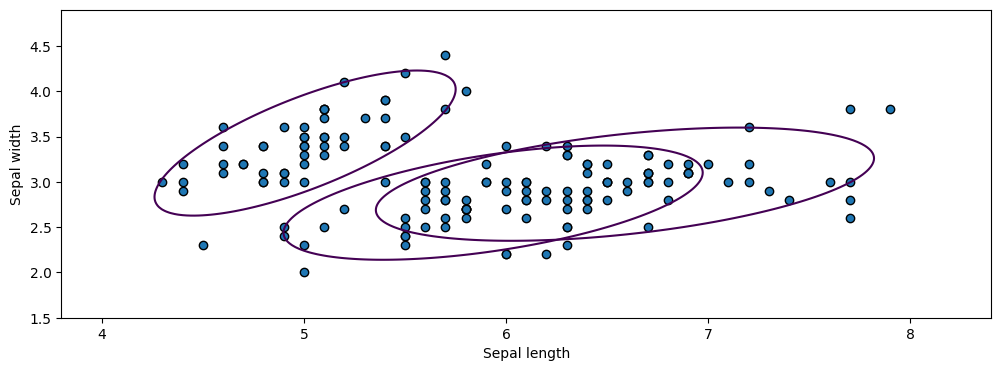

In [5]:
for k in range(K):
    plt.contour(xx, yy, contours[k], levels=np.logspace(0, 1, 1))

plt.scatter(X[:, 0], X[:, 1], edgecolors='k', cmap=plt.cm.Paired)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')

plt.show()

# From Labeled to Unlabeled Clustering

Next, we want to train a GMM clustering model from unlabeled data.

Our strategy will be to jointly learn cluster parameters and labels:

1. We will define an objective that does not require cluster labels $z^{(i)}$.
2. We will define an optimizer that jointly infers both labels $z^{(i)}$ and cluster parameters $\mu_k, \Sigma_k$.

# EM in Gaussian Mixture Models

EM learns the parameters $\theta$ of a Gaussian mixture model $P_\theta(x,z)$ over a dataset $\mathcal{D} = \{x^{(i)} \mid i = 1,2,...,n\}$ as follows.

For $t=0,1,2,\ldots$, repeat until convergence:
1. (__E-Step__) For each $x^{(i)} \in \mathcal{D}$ compute $P_{\theta_t}(z|x^{(i)})$
2. (__M-Step__) Compute parameters $\mu_k, \Sigma_k, \phi_k$ using the below formulas

\begin{align*}
\mu_k & = \frac{\sum_{i=1}^n P(z=k|x^{(i)}) x^{(i)}}{n_k} \\
\Sigma_k & = \frac{\sum_{i=1}^n P(z=k|x^{(i)}) (x^{(i)} - \mu_k)(x^{(i)} - \mu_k)^\top}{n_k} \\
n_k & = \sum_{i=1}^n P(z=k|x^{(i)}) \\
\end{align*}
Intuitively, the optimal mean and covariance are the emprical mean and convaraince of the dataset $\mathcal{D}$ when each element $x^{(i)}$ has a weight $P(z=k|x^{(i)})$.

Similarly, we can show that the class priors are
\begin{align*}
\phi_k & = \frac{n_k}{n} \\
n_k & = \sum_{i=1}^n P(z=k|x^{(i)})
\end{align*}

# Generalization in Probabilistic Models


Consider the following dataset, consisting of a mixture of Gaussians.

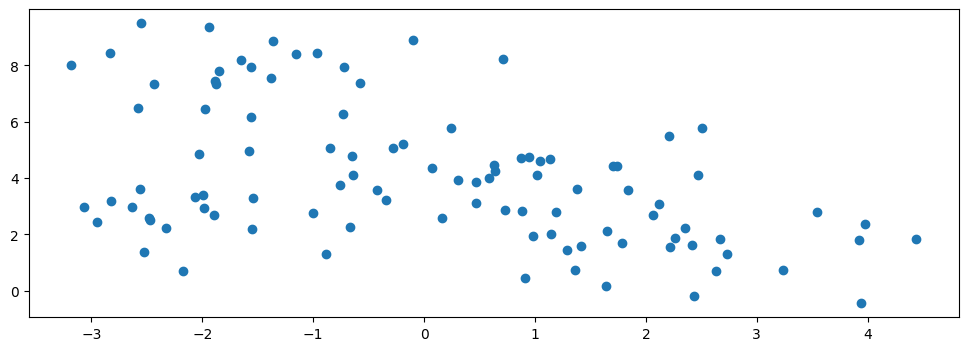

In [6]:
import numpy as np
from sklearn import datasets
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [12, 4]

# generate 150 random points
np.random.seed(0)
X_all, y_all = datasets.make_blobs(150, centers=4)

# use the first 100 points as the main dataset
X, y = X_all[:100], y_all[:100]
plt.scatter(X[:,0], X[:,1])

We know the true labels of these clusers, and we can visualize them.

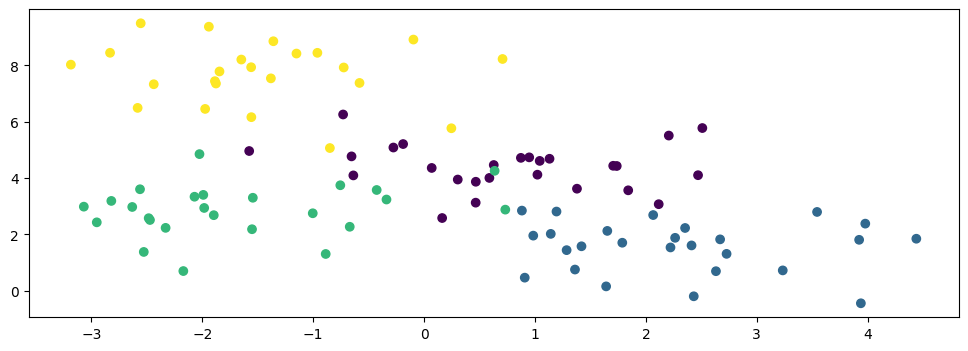

In [7]:
plt.scatter(X[:,0], X[:,1], c=y)

We will also keep 50 points as a holdout set.

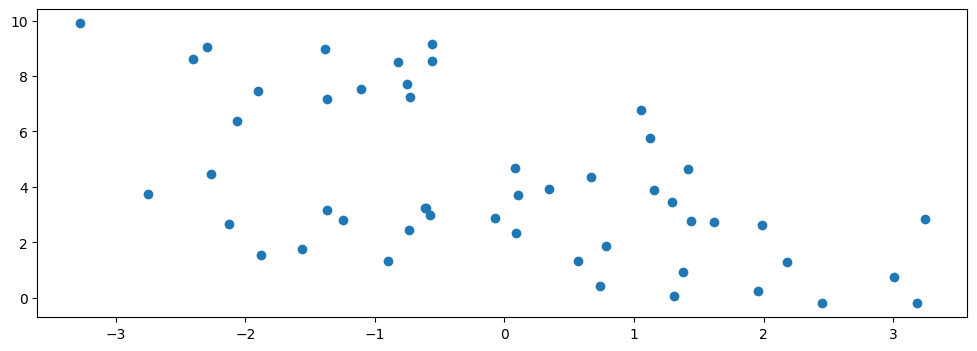

In [8]:
# use the last 50 points as a holdout set
X_holdout, y_holdout = X_all[100:], y_all[100:]
plt.scatter(X_holdout[:,0], X_holdout[:,1])

# Underfitting in Unsupervised Learning

Underfitting happens when we are not able to fully learn the signal hidden in the data.

In the context of GMMs, this means not capturing all the clusters in the data.

Let's fit a GMM on our toy dataset.

In [9]:
# fit a GMM
from sklearn import mixture
model = mixture.GaussianMixture(n_components=2)
model.fit(X)

GaussianMixture(n_components=2)

The model finds two distinct components in the data, but they fail to capture the true structure.

We can also measure the value of our objective (the log-likelihood) on the training and holdout sets.

Training Set Log-Likelihood (higher is better): -4.08
Holdout Set Log-Likelihood (higher is better): -4.07


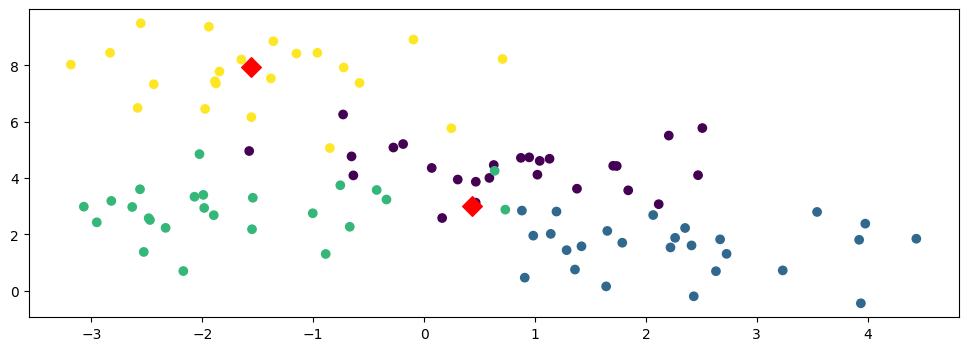

In [10]:
plt.scatter(X[:,0], X[:,1], c=y)
plt.scatter(model.means_[:,0], model.means_[:,1], marker='D', c='r', s=100)
print('Training Set Log-Likelihood (higher is better): %.2f' % model.score(X))
print('Holdout Set Log-Likelihood (higher is better): %.2f' % model.score(X_holdout))

Consider now what happens if we further increase the number of clusters.

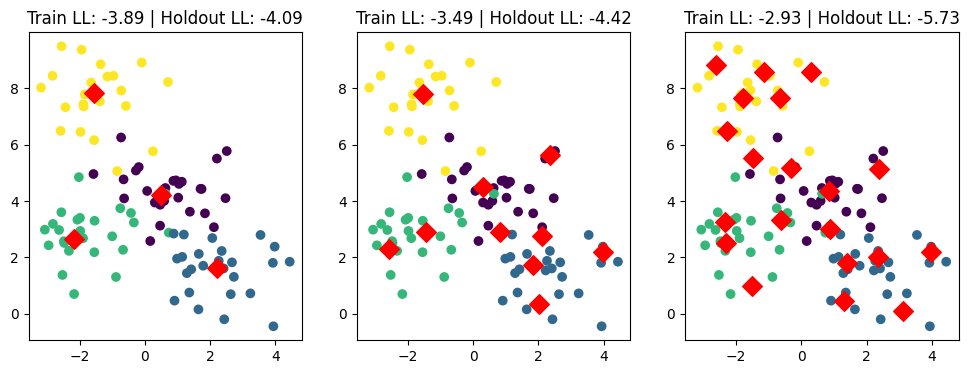

In [11]:
Ks = [4, 10, 20]
f, axes = plt.subplots(1,3)
for k, ax in zip(Ks, axes):
    model = mixture.GaussianMixture(n_components=k)
    model.fit(X)
    ax.scatter(X[:,0], X[:,1], c=y)
    ax.scatter(model.means_[:,0], model.means_[:,1], marker='D', c='r', s=100)
    ax.set_title('Train LL: %.2f | Holdout LL: %.2f' % (model.score(X), model.score(X_holdout)))

# Overfitting in Unsupervised Learning

Overfitting happens when we fit the noise, but not the signal.

In our example, this means fitting small, local noise clusters rather than the true global clusters.

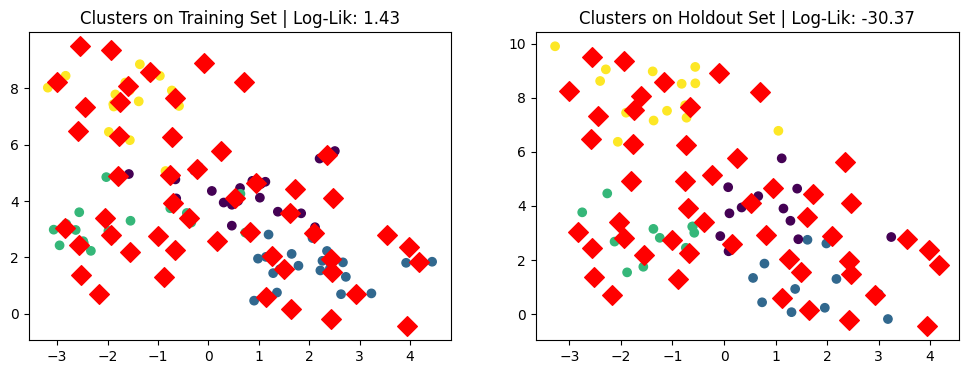

In [12]:
model = mixture.GaussianMixture(n_components=50)
model.fit(X)

plt.subplot(121)
plt.title('Clusters on Training Set | Log-Lik: %.2f' % model.score(X))
plt.scatter(X[:,0], X[:,1], c=y)
plt.scatter(model.means_[:,0], model.means_[:,1], marker='D', c='r', s=100)

plt.subplot(122)
plt.title('Clusters on Holdout Set | Log-Lik: %.2f' % model.score(X_holdout))
plt.scatter(X_holdout[:,0], X_holdout[:,1], c=y_holdout)
plt.scatter(model.means_[:,0], model.means_[:,1], marker='D', c='r', s=100)

# Measuring Generalization Using Log-Likelihood

Probabilistic unsupervised models optimize an objective that can be used to detect overfitting and underfitting by comparing performance between training and holdout sets.

Below, we visualize the performance (measured via negative log-likelihood) on training and holdout sets as $K$ increases.

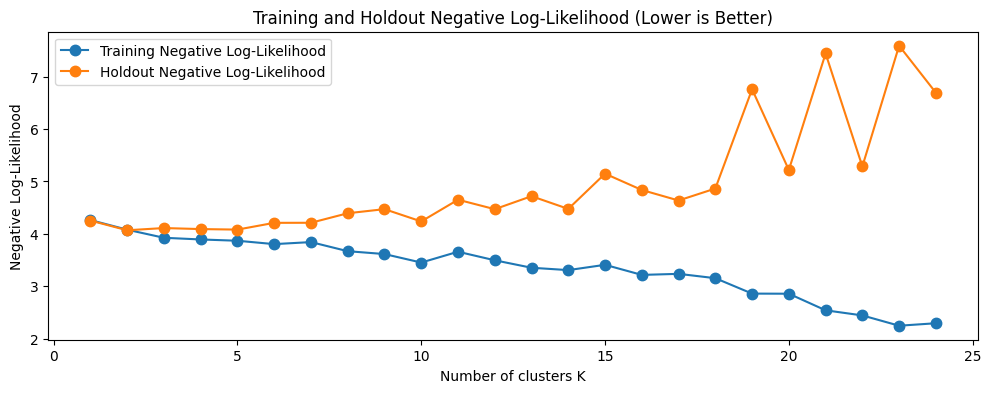

In [13]:
Ks, training_objs, holdout_objs = range(1,25), [], []
for k in Ks:
    model = mixture.GaussianMixture(n_components=k)
    model.fit(X)
    training_objs.append(-model.score(X))
    holdout_objs.append(-model.score(X_holdout))

plt.plot(Ks, training_objs, '.-', markersize=15)
plt.plot(Ks, holdout_objs, '.-', markersize=15)
plt.xlabel("Number of clusters K")
plt.ylabel("Negative Log-Likelihood")
plt.title("Training and Holdout Negative Log-Likelihood (Lower is Better)")
plt.legend(['Training Negative Log-Likelihood', 'Holdout Negative Log-Likelihood'])

__Warning__: This process doesn't work as well as in supervised learning

For example, detecting overfitting with larger datasets will be paradoxically harder (try it!)

# Summary

* We can reduce clustering to fitting a GMM with latent $z$
* A GMM can be fit without labels via EM: we alternate between hallucinating labels and optimizing the model.
* A probabilistic model can detect overfitting by comparing the likelihood of training data vs. that of holdout data.